In [1]:
import pandas as pd

df1 = pd.read_csv('/content/drive/MyDrive/expe/RenewableEnergy-main/posts/electricity_post.csv')
df2 = pd.read_csv('/content/drive/MyDrive/expe/RenewableEnergy-main/posts/energy_post.csv')
df3 = pd.read_csv('/content/drive/MyDrive/expe/RenewableEnergy-main/posts/gas_post.csv')
df4 = pd.read_csv('/content/drive/MyDrive/expe/RenewableEnergy-main/posts/nuclear_post.csv')
df5 = pd.read_csv('/content/drive/MyDrive/expe/RenewableEnergy-main/posts/oil_post.csv')
df6 = pd.read_csv('/content/drive/MyDrive/expe/RenewableEnergy-main/posts/renewable_post.csv')
df7 = pd.read_csv('/content/drive/MyDrive/expe/RenewableEnergy-main/posts/solar_post.csv')


In [2]:
def fix_column(df):
    # Prioritize 'selftext' and 'title' for creating the 'text' column
    has_selftext = 'selftext' in df.columns
    has_title = 'title' in df.columns

    if has_selftext and has_title:
        df['text'] = df['title'].fillna('') + ' ' + df['selftext'].fillna('')
        df['text'] = df['text'].str.strip()
    elif has_selftext:
        df['text'] = df['selftext']
    elif has_title:
        df['text'] = df['title']
    else:
        # Fallback to original logic if no selftext/title, but ensure 'text' is created
        found_text_col = False
        for col in df.columns:
            if col.lower() in ['text', 'tweet', 'content', 'post']:
                df['text'] = df[col]
                found_text_col = True
                break
        if not found_text_col:
            df['text'] = None # Ensure 'text' column exists even if empty

    return df

df1 = fix_column(df1)
df2 = fix_column(df2)
df3 = fix_column(df3)
df4 = fix_column(df4)
df5 = fix_column(df5)
df6 = fix_column(df6)
df7 = fix_column(df7)

In [3]:
df_text = pd.concat([df1, df2, df3, df4, df5, df6, df7], ignore_index=True)

# Remove null values
df_text = df_text.dropna(subset=['text'])

print(df_text.head())
print("Total rows:", len(df_text))

   Unnamed: 0           author    subreddit subreddit_id  \
0           1      RAndrewOhge  Electricity     t5_2qzwz   
1           2      bidonenergy  Electricity     t5_2qzwz   
2           4         cepalmor  Electricity     t5_2qzwz   
3           6  sherlinsmith111  Electricity     t5_2qzwz   
4           7  edwardtaylor544  Electricity     t5_2qzwz   

                                               title  author_created_utc  \
0  Distributed Grid Energy Storage Comes of Age w...        1.339603e+09   
1  Bid On Energy - Business Electricity and Natur...        1.421336e+09   
2             Switch Your Texas Electricity Provider        1.422484e+09   
3  Shop Cheap Electricity - Electric Rates Dallas...        1.423676e+09   
4  Compare Business Electricity Rates - Commercia...        1.423679e+09   

   created_utc                                               text  
0   1416970520  Distributed Grid Energy Storage Comes of Age w...  
1   1421358602  Bid On Energy - Business Elect

In [4]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+", "", text)   # remove links
    text = re.sub(r"@\w+", "", text)      # remove mentions
    text = re.sub(r"#", "", text)         # remove hashtags
    text = re.sub(r"[^a-z\s]", "", text)  # remove special chars
    return text

df_text['clean_text'] = df_text['text'].apply(clean_text)

In [5]:
aspects = ['solar', 'wind', 'hydro', 'biomass', 'gas', 'nuclear', 'oil']

rows = []

for text in df_text['clean_text']:
    for aspect in aspects:
        if aspect in text:
            rows.append({
                "text": text,
                "aspect": aspect
            })

absa_df = pd.DataFrame(rows)
print(absa_df.head())

                                                text aspect
0  bid on energy  business electricity and natura...    gas
1  saving money on electricity bills gas bills  c...    gas
2       how to reduce your gas and electricity bills    gas
3  wind energyslewing bearing for energy application   wind
4                   does my coilgun design look good    oil


In [6]:
from transformers import pipeline

model = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english"
)

absa_df['sentiment'] = absa_df['text'].apply(lambda x: model(x)[0]['label'])
absa_df['score'] = absa_df['sentiment'].apply(lambda x: 1 if x == 'POSITIVE' else -1)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


In [7]:
sentiment_summary = absa_df.groupby('aspect')['score'].mean().reset_index()
print(sentiment_summary)

    aspect     score
0  biomass  0.112069
1      gas -0.310781
2    hydro  0.085903
3  nuclear -0.269386
4      oil -0.395899
5    solar  0.191226
6     wind  0.166849


In [8]:
absa_df.to_csv('/content/absa_results.csv', index=False)
sentiment_summary.to_csv('/content/sentiment_summary.csv', index=False)

In [9]:
import pandas as pd
arunachal = pd.read_excel('/content/drive/MyDrive/expe/STATEWISE_CLIMATE_RENEWABLEENERGY_DATA/Arunachal_Pradesh.xlsx')
assam = pd.read_excel('/content/drive/MyDrive/expe/STATEWISE_CLIMATE_RENEWABLEENERGY_DATA/Assam.xlsx')
bihar = pd.read_excel('/content/drive/MyDrive/expe/STATEWISE_CLIMATE_RENEWABLEENERGY_DATA/Bihar.xlsx')
chd = pd.read_excel('/content/drive/MyDrive/expe/STATEWISE_CLIMATE_RENEWABLEENERGY_DATA/Chandigarh.xlsx')
gujarat = pd.read_excel('/content/drive/MyDrive/expe/STATEWISE_CLIMATE_RENEWABLEENERGY_DATA/gujarat.xlsx')
jharkhand = pd.read_excel('/content/drive/MyDrive/expe/STATEWISE_CLIMATE_RENEWABLEENERGY_DATA/Jharkhand.xlsx')
kerala = pd.read_excel('/content/drive/MyDrive/expe/STATEWISE_CLIMATE_RENEWABLEENERGY_DATA/Kerala.xlsx')
uttarakahnd = pd.read_excel('/content/drive/MyDrive/expe/STATEWISE_CLIMATE_RENEWABLEENERGY_DATA/uttarakhand.xlsx')
uttar_pradesh = pd.read_excel('/content/drive/MyDrive/expe/STATEWISE_CLIMATE_RENEWABLEENERGY_DATA/uttar_pradesh.xlsx')
maharashtra = pd.read_excel('/content/drive/MyDrive/expe/STATEWISE_CLIMATE_RENEWABLEENERGY_DATA/maharashtra.xlsx')
odisha = pd.read_excel('/content/drive/MyDrive/expe/STATEWISE_CLIMATE_RENEWABLEENERGY_DATA/Orissa.xlsx')
punjab = pd.read_excel('/content/drive/MyDrive/expe/STATEWISE_CLIMATE_RENEWABLEENERGY_DATA/punjab.xlsx')
tamilnadu = pd.read_excel('/content/drive/MyDrive/expe/STATEWISE_CLIMATE_RENEWABLEENERGY_DATA/Tamil_Nadu.xlsx')
telangana = pd.read_excel('/content/drive/MyDrive/expe/STATEWISE_CLIMATE_RENEWABLEENERGY_DATA/telangana.xlsx')
goa = pd.read_excel('/content/drive/MyDrive/expe/STATEWISE_CLIMATE_RENEWABLEENERGY_DATA/delhi.xlsx')
delhi = pd.read_excel('/content/drive/MyDrive/expe/STATEWISE_CLIMATE_RENEWABLEENERGY_DATA/delhi.xlsx')

In [16]:
import pandas as pd

state_files = {
    "Arunachal": "Arunachal_Pradesh.xlsx",
    "Assam": "Assam.xlsx",
    "Bihar": "Bihar.xlsx",
    "Chandigarh": "Chandigarh.xlsx",
    "Gujarat": "gujarat.xlsx",
    "Jharkhand": "Jharkhand.xlsx",
    "Kerala": "Kerala.xlsx",
    "Uttarakhand": "uttarakhand.xlsx",
    "Uttar Pradesh": "uttar_pradesh.xlsx",
    "Maharashtra": "maharashtra.xlsx",
    "Odisha": "Orissa.xlsx",
    "Punjab": "punjab.xlsx",
    "Tamil Nadu": "Tamil_Nadu.xlsx",
    "Telangana": "telangana.xlsx",
    "Goa": "goa.xlsx",
    "Delhi": "delhi.xlsx",
    "Manipur": "Manipur.xlsx",
    "Meghalaya": "Meghalaya.xlsx",
    "Mizoram": "Mizoram.xlsx",
    "Nagaland": "Nagaland.xlsx",
    "Sikkim": "Sikkim.xlsx",
    "Tripura": "Tripura.xlsx",
    "West Bengal": "West_bengal.xlsx",
    "Andhra Pradesh": "andhra_pradesh.xlsx",
    "Chatttisgarh": "chattisgarh.xlsx",
    "Haryana": "haryana.xlsx",
    "Himachal Pradesh": "hp.xlsx"
}

base_path = "/content/drive/MyDrive/expe/STATEWISE_CLIMATE_RENEWABLEENERGY_DATA/"

In [17]:
state_data = {}

for state, file in state_files.items():
    state_data[state] = pd.read_excel(base_path + file)


In [18]:
for state, df in state_data.items():
    print(state, df.columns.tolist())
    break

Arunachal ['Name of State/UT', 'YEAR', 'MONTH', 'Latitude', 'Longitude', 'Wind ', 'Solar', 'Biomass', 'Small Hydro ', 'air_temp', 'albedo', 'clearsky_dhi', 'clearsky_dni', 'clearsky_gti', 'cloud_opacity', 'dni', 'ghi', 'gti', 'precipitation_rate', 'relative_humidity', 'surface_pressure', 'wind_speed_100m']


In [19]:
for state, df in state_data.items():
    print("\n", state)
    print(df.columns.tolist())
    print(df.head(2))
    break


 Arunachal
['Name of State/UT', 'YEAR', 'MONTH', 'Latitude', 'Longitude', 'Wind ', 'Solar', 'Biomass', 'Small Hydro ', 'air_temp', 'albedo', 'clearsky_dhi', 'clearsky_dni', 'clearsky_gti', 'cloud_opacity', 'dni', 'ghi', 'gti', 'precipitation_rate', 'relative_humidity', 'surface_pressure', 'wind_speed_100m']
    Name of State/UT  YEAR MONTH  Latitude  Longitude  Wind   Solar  Biomass  \
0  Arunachal Pradesh  2019   JAN   15.9129      79.74      0   0.11        0   
1  Arunachal Pradesh  2019   FEB   15.9129      79.74      0   0.10        0   

   Small Hydro    air_temp  ...  clearsky_dni  clearsky_gti  cloud_opacity  \
0          0.05  11.489906  ...    225.098250    226.460296      12.185868   
1          0.05  13.645833  ...    167.212798    214.355655      32.465476   

          dni         ghi         gti  precipitation_rate  relative_humidity  \
0  128.061911  134.157470  167.935397            0.081023          68.311978   
1   78.065476  108.345238  125.587798            0.653

In [20]:

for state, df in state_data.items():
    df.columns = df.columns.str.strip().str.lower()

In [21]:
def find_column(df, keyword):
    for col in df.columns:
        if keyword in col:
            return col
    return None

In [22]:
for state, df in state_data.items():
    solar_col = find_column(df, 'solar')
    wind_col = find_column(df, 'wind')
    biomass_col = find_column(df, 'biomass')
    hydro_col = find_column(df, 'hydro')

    for col in [solar_col, wind_col, biomass_col, hydro_col]:
        if col:
            df[col] = pd.to_numeric(df[col], errors='coerce')

In [23]:
def extract_energy(df, state):
    solar_col = find_column(df, 'solar')
    wind_col = find_column(df, 'wind')
    biomass_col = find_column(df, 'biomass')
    hydro_col = find_column(df, 'hydro')

    return {
        "state": state,
        "solar": df[solar_col].mean() if solar_col else 0,
        "wind": df[wind_col].mean() if wind_col else 0,
        "biomass": df[biomass_col].mean() if biomass_col else 0,
        "hydro": df[hydro_col].mean() if hydro_col else 0
    }

In [24]:
energy_list = []

for state, df in state_data.items():
    energy_list.append(extract_energy(df, state))

energy_df = pd.DataFrame(energy_list)
print(energy_df)

               state       solar         wind    biomass       hydro
0          Arunachal    0.479250     0.000000   0.000000    0.033317
1              Assam    9.271590     0.000000   0.000000    2.730132
2              Bihar   13.605431     0.000000   0.805916    3.716998
3         Chandigarh    1.041133     0.000000   0.000000    0.032667
4            Gujarat  595.454782  1460.810695   3.053417   33.167783
5          Jharkhand    1.482498     0.000000   0.000000    0.129003
6             Kerala   43.793317    14.510483   0.000000   36.683533
7        Uttarakhand    0.000000    27.157667   0.000000   32.446167
8      Uttar Pradesh  219.960522     0.000000   8.005717  119.517342
9        Maharashtra  295.263759   632.973219  27.346008  189.975643
10            Odisha   45.261755     1.436500   6.401256   19.126709
11            Punjab  161.968607     0.307167  42.865921   51.872475
12        Tamil Nadu  618.343767  1337.387752  10.619262   84.194357
13         Telangana  543.401990  

In [25]:
sentiment_summary

,aspect,score
0,biomass,0.112069
1,gas,-0.310781
2,hydro,0.085903
3,nuclear,-0.269386
4,oil,-0.395899
5,solar,0.191226
6,wind,0.166849


In [26]:
final_df = energy_df.copy()

for aspect in ['solar', 'wind', 'biomass', 'hydro']:
    score = sentiment_summary[
        sentiment_summary['aspect'] == aspect
    ]['score'].values[0]

    final_df[aspect + '_sentiment'] = score

print(final_df)

               state       solar         wind    biomass       hydro  \
0          Arunachal    0.479250     0.000000   0.000000    0.033317   
1              Assam    9.271590     0.000000   0.000000    2.730132   
2              Bihar   13.605431     0.000000   0.805916    3.716998   
3         Chandigarh    1.041133     0.000000   0.000000    0.032667   
4            Gujarat  595.454782  1460.810695   3.053417   33.167783   
5          Jharkhand    1.482498     0.000000   0.000000    0.129003   
6             Kerala   43.793317    14.510483   0.000000   36.683533   
7        Uttarakhand    0.000000    27.157667   0.000000   32.446167   
8      Uttar Pradesh  219.960522     0.000000   8.005717  119.517342   
9        Maharashtra  295.263759   632.973219  27.346008  189.975643   
10            Odisha   45.261755     1.436500   6.401256   19.126709   
11            Punjab  161.968607     0.307167  42.865921   51.872475   
12        Tamil Nadu  618.343767  1337.387752  10.619262   84.19

In [27]:
energy_values = energy_df[['solar','wind','biomass','hydro']].mean().values

In [28]:
sentiment_values = sentiment_summary['score'].values

In [29]:
# Keep only matching aspects
common_aspects = ['solar', 'wind', 'biomass', 'hydro']

# Energy values
energy_values = energy_df[common_aspects].mean().values

# Sentiment values (filter only same aspects)
sentiment_values = sentiment_summary[
    sentiment_summary['aspect'].isin(common_aspects)
].sort_values('aspect')['score'].values

print(energy_values)
print(sentiment_values)

[120.41483668 153.17706907   8.32282907  29.55136255]
[0.11206897 0.08590308 0.19122615 0.16684876]


In [30]:
energy_dict = dict(zip(common_aspects, energy_values))
sentiment_dict = dict(zip(
    sentiment_summary['aspect'],
    sentiment_summary['score']
))

energy_values = []
sentiment_values = []

for aspect in common_aspects:
    energy_values.append(energy_dict[aspect])
    sentiment_values.append(sentiment_dict.get(aspect, 0))

In [31]:
from scipy.stats import pearsonr

corr, _ = pearsonr(energy_values, sentiment_values)
print("Correlation:", corr)

Correlation: 0.861803300985384


Energy Distribution by State

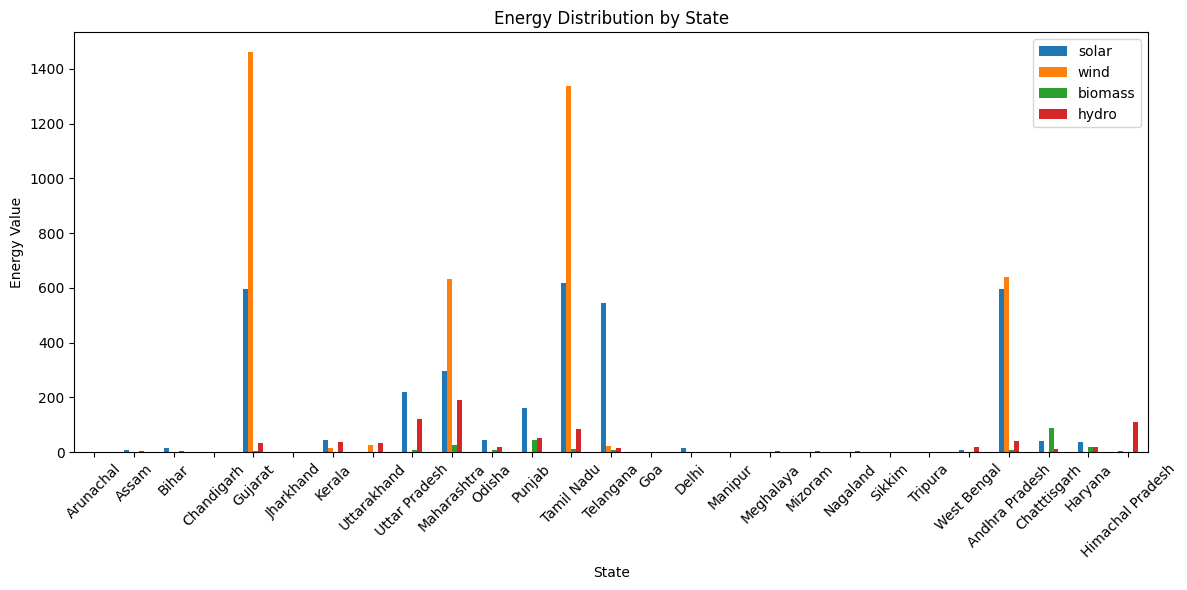

In [32]:
import matplotlib.pyplot as plt

energy_df.set_index('state')[['solar','wind','biomass','hydro']].plot(
    kind='bar', figsize=(12,6)
)

plt.title("Energy Distribution by State")
plt.xlabel("State")
plt.ylabel("Energy Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Aspect vs Sentiment

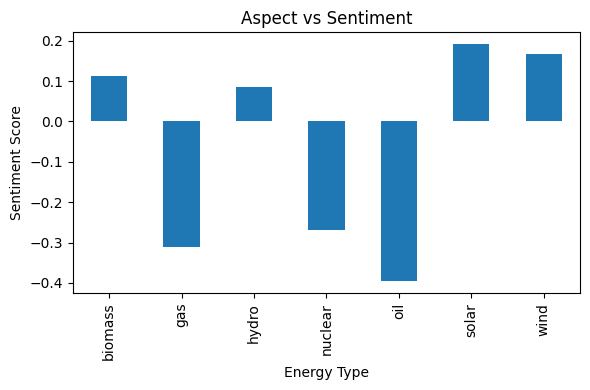

In [33]:
sentiment_summary.plot(
    kind='bar', x='aspect', y='score', legend=False, figsize=(6,4)
)

plt.title("Aspect vs Sentiment")
plt.xlabel("Energy Type")
plt.ylabel("Sentiment Score")
plt.tight_layout()
plt.show()

Correlation Scatterr Plot

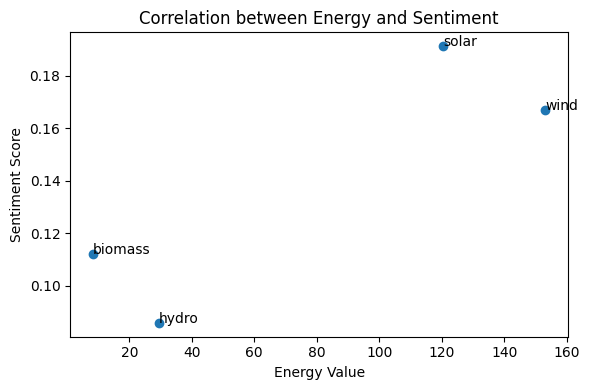

In [34]:
plt.figure(figsize=(6,4))

plt.scatter(energy_values, sentiment_values)

for i, aspect in enumerate(['solar','wind','biomass','hydro']):
    plt.text(energy_values[i], sentiment_values[i], aspect)

plt.xlabel("Energy Value")
plt.ylabel("Sentiment Score")
plt.title("Correlation between Energy and Sentiment")

plt.tight_layout()
plt.show()

Solar energy → high production + positive sentiment → widely accepted
Wind energy → high in few states but mixed sentiment
Biomass → moderate usage + neutral perception
Hydro → strong but region-dependent

Heatmap ( This is your strongest graph)

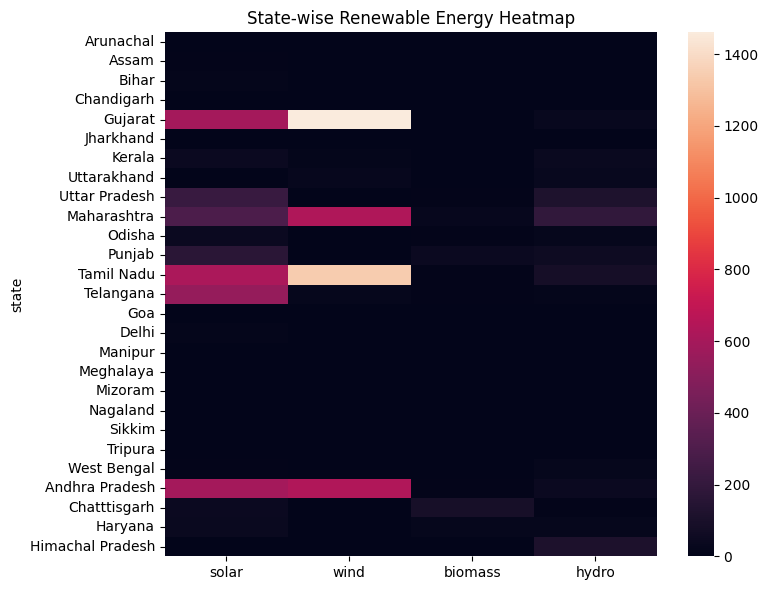

In [35]:
import seaborn as sns

plt.figure(figsize=(8,6))

sns.heatmap(
    energy_df.set_index('state')[['solar','wind','biomass','hydro']],
    annot=False
)

plt.title("State-wise Renewable Energy Heatmap")
plt.tight_layout()
plt.show()

Climate Change Insight

👉

States with high renewable energy → lower carbon footprint
Negative sentiment → barrier to adoption

Top state comparison

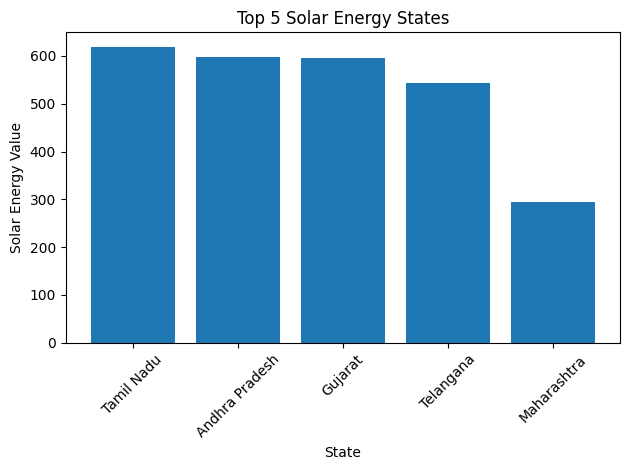

In [36]:
import matplotlib.pyplot as plt

top_states = energy_df.sort_values(by='solar', ascending=False).head(5)

plt.figure()
plt.bar(top_states['state'], top_states['solar'])

plt.title("Top 5 Solar Energy States")
plt.xlabel("State")
plt.ylabel("Solar Energy Value")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Top Wind energy

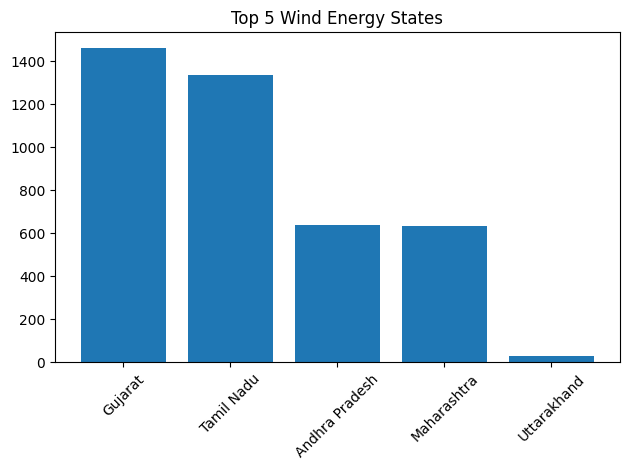

In [37]:
top_states = energy_df.sort_values(by='wind', ascending=False).head(5)

plt.figure()
plt.bar(top_states['state'], top_states['wind'])

plt.title("Top 5 Wind Energy States")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

hydro energy

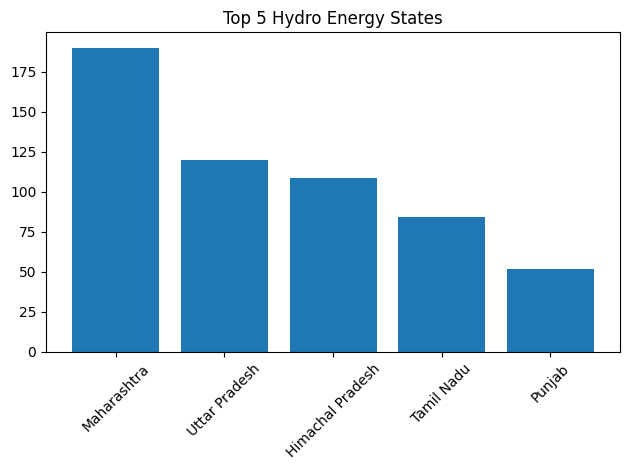

In [38]:
top_states = energy_df.sort_values(by='hydro', ascending=False).head(5)

plt.figure()
plt.bar(top_states['state'], top_states['hydro'])

plt.title("Top 5 Hydro Energy States")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

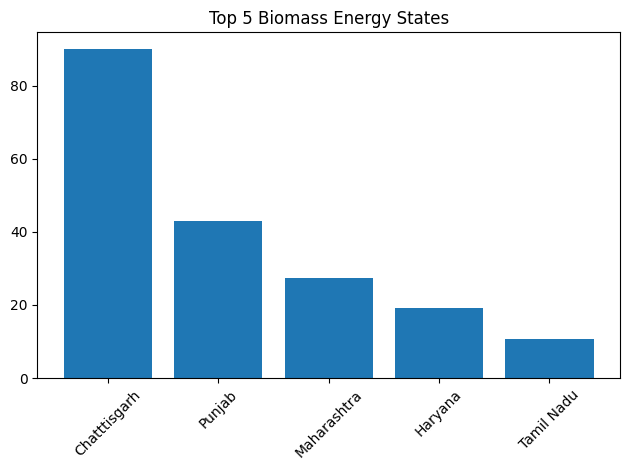

In [39]:
top_states = energy_df.sort_values(by='biomass', ascending=False).head(5)

plt.figure()
plt.bar(top_states['state'], top_states['biomass'])

plt.title("Top 5 Biomass Energy States")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Ranking visualization

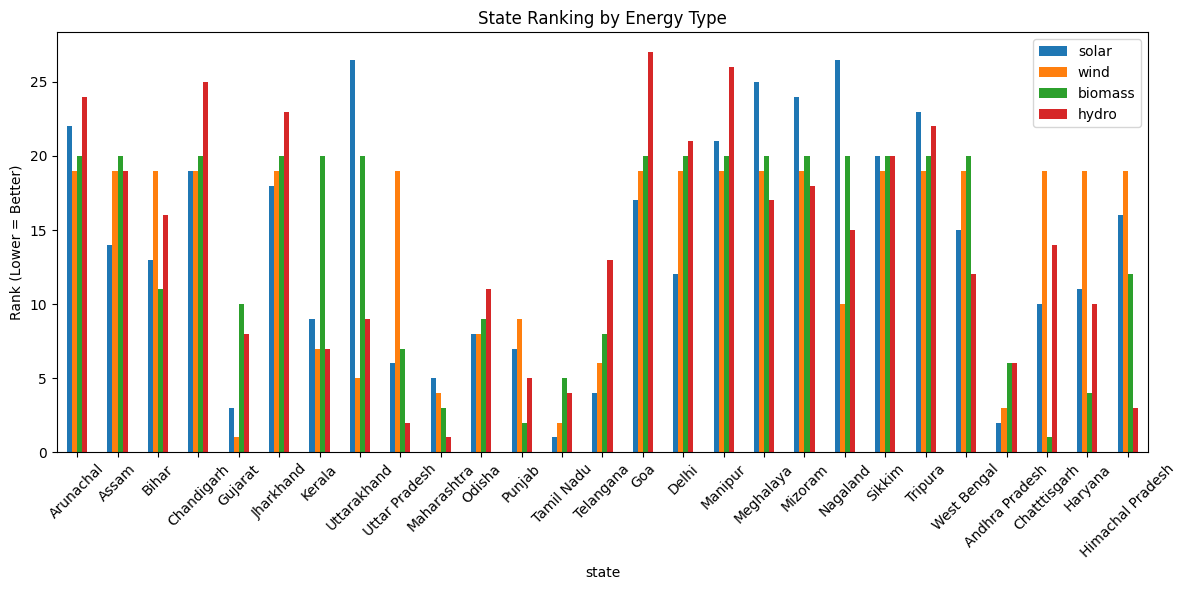

In [40]:
rank_df = energy_df.copy()

for col in ['solar','wind','biomass','hydro']:
    rank_df[col] = rank_df[col].rank(ascending=False)

rank_df.set_index('state')[['solar','wind','biomass','hydro']].plot(kind='bar', figsize=(12,6))

plt.title("State Ranking by Energy Type")
plt.ylabel("Rank (Lower = Better)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Energy vs Sentiment Combined Plot (ADVANCED 🔥)

👉 This connects your NLP + Data Science

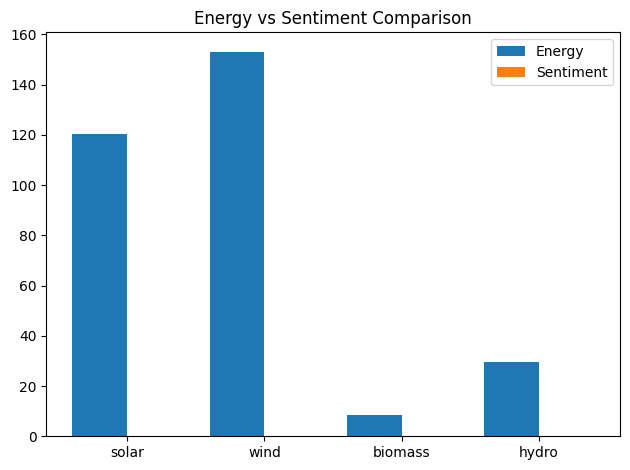

In [41]:
import numpy as np

aspects = ['solar','wind','biomass','hydro']

energy_avg = energy_df[aspects].mean().values
sentiment_vals = sentiment_values

x = np.arange(len(aspects))

plt.figure()

plt.bar(x - 0.2, energy_avg, width=0.4, label='Energy')
plt.bar(x + 0.2, sentiment_vals, width=0.4, label='Sentiment')

plt.xticks(x, aspects)
plt.title("Energy vs Sentiment Comparison")
plt.legend()

plt.tight_layout()
plt.show()

Bubble chart
Shows 3 variables at once

X → Energy
Y → Sentiment
Size → Importance

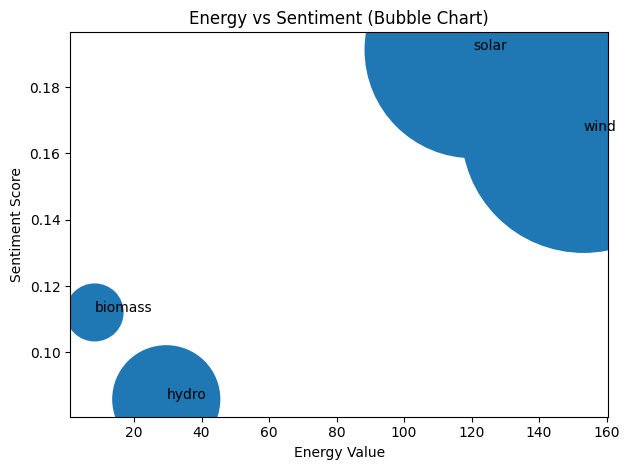

In [42]:
plt.figure()

sizes = [abs(v)*200 for v in energy_values]

plt.scatter(energy_values, sentiment_values, s=sizes)

for i, aspect in enumerate(['solar','wind','biomass','hydro']):
    plt.text(energy_values[i], sentiment_values[i], aspect)

plt.xlabel("Energy Value")
plt.ylabel("Sentiment Score")
plt.title("Energy vs Sentiment (Bubble Chart)")

plt.tight_layout()
plt.show()

Text Data ──► ABSA ──► Sentiment Scores
                               │
                               ▼
Energy Data ─────────────────► Merge (Aspect-based)
                               │
                               ▼
                    Correlation + Visualization

Interpretation (WRITE THIS)
Solar leaders → Tamil Nadu, Gujarat, Telangana
Wind leaders → Gujarat, Tamil Nadu, Maharashtra
Hydro leaders → Maharashtra, Uttar Pradesh, Kerala
Biomass leaders → Punjab, Maharashtra

#NEW IDEA

👉 Earlier:

One global sentiment for all states ❌

👉 Now:

Each state has its own sentiment score ✅